# 08　一致性判定：五个案例的门限

`07` 把每个案例解出来，本册只做一件事：**拿实测指标对照门限**，给出 PASS / FAIL。

| 案例 | 判据 | 门限 | 离线仿真值 |
|---|---|---|---|
| ASK4 / 8PSK / 16QAM | 误码 | 0 | 0 |
| | EVM max | ≤ 8% | 1.3~3.6% |
| | 判决余量 min | ≥ 0.85 | 0.91~0.92 |
| AM | 相关系数 | \|corr\| ≥ 0.98 | 0.999 |
| | 归一化 RMSE | ≤ 10% | 4.5% |
| | μ 实测/设定 | 1 ± 0.10 | 1.04 |
| FM | 相关系数 | \|corr\| ≥ 0.98 | 0.999 |
| | 归一化 RMSE | ≤ 10% | 6.0% |
| | Δf 实测/设定 | 1 ± 0.10 | 0.99 |
| | 幅度纹波 | ≤ 10% | 6.1% |

门限由仿真留 2~3 倍余量：板上多了 DAC/ADC 量化、环回损耗和时钟抖动，指标会变差，
但不该跨一个量级。门限写在 `mod_cases.LIM`，改动只有一处。

## 1　重新解调并判定

In [1]:
import os
import sys

MOD_DIR = "/home/xilinx/modulation"
NB_DIR = "/home/xilinx/jupyter_notebooks/modulation"
QPSK_DIR = "/home/xilinx/qpsk"
for _p in (MOD_DIR, QPSK_DIR):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

SAVE_DIR = NB_DIR if os.path.isdir(NB_DIR) else MOD_DIR


def npz_path(name):
    """本文件夹优先，模块目录兜底。"""
    for d in (NB_DIR, MOD_DIR):
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return os.path.join(SAVE_DIR, name)

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

CASES = ("ASK4", "8PSK", "16QAM", "AM", "FM")
res = {}
for name in CASES:
    p = npz_path("mod_06_%s.npz" % name)
    if os.path.exists(p):
        res[name] = C.load_and_demod(p)
    else:
        print("缺 %s，跳过 %s" % (p, name))

In [2]:
print("%-6s %-4s %-5s  %s" % ("案例", "类型", "结果", "实测 vs 门限"))
print("-" * 92)
nbad = 0
for name in CASES:
    if name not in res:
        print("%-6s %-4s %-5s  %s" % (name, "?", "SKIP", "缺 mod_06_%s.npz" % name))
        continue
    r = res[name]
    ok, det = C.verdict(r)
    nbad += 0 if ok else 1
    print("%-6s %-4s %-5s  %s"
          % (name, "数字" if r["kind"] == "digital" else "模拟",
             "PASS" if ok else "FAIL", det))

print("-" * 92)
print("%d 个案例：%s" % (len(res), "全部 PASS" if nbad == 0
                         else "%d 个 FAIL" % nbad))

案例     类型   结果     实测 vs 门限
--------------------------------------------------------------------------------------------
ASK4   数字   PASS   BER 0/9216，EVM max 2.35%（≤8.0），余量 min 0.940（≥0.85）
8PSK   数字   PASS   BER 0/13824，EVM max 2.24%（≤8.0），余量 min 0.903（≥0.85）
16QAM  数字   PASS   BER 0/9216，EVM max 2.19%（≤8.0），余量 min 0.863（≥0.85）
AM     模拟   PASS   corr +0.9996（|·|≥0.98），rmse 3.2%（≤10%），比值 1.010（1±0.10）
FM     模拟   PASS   corr +1.0000（|·|≥0.98），rmse 2.2%（≤10%），比值 0.977（1±0.10），纹波 2.5%（≤10%）
--------------------------------------------------------------------------------------------
5 个案例：全部 PASS


**应该看到**：五个案例全 PASS。若有 FAIL，先看下面这张表定位，再回 `07` 对应小节。

## 2　指标图

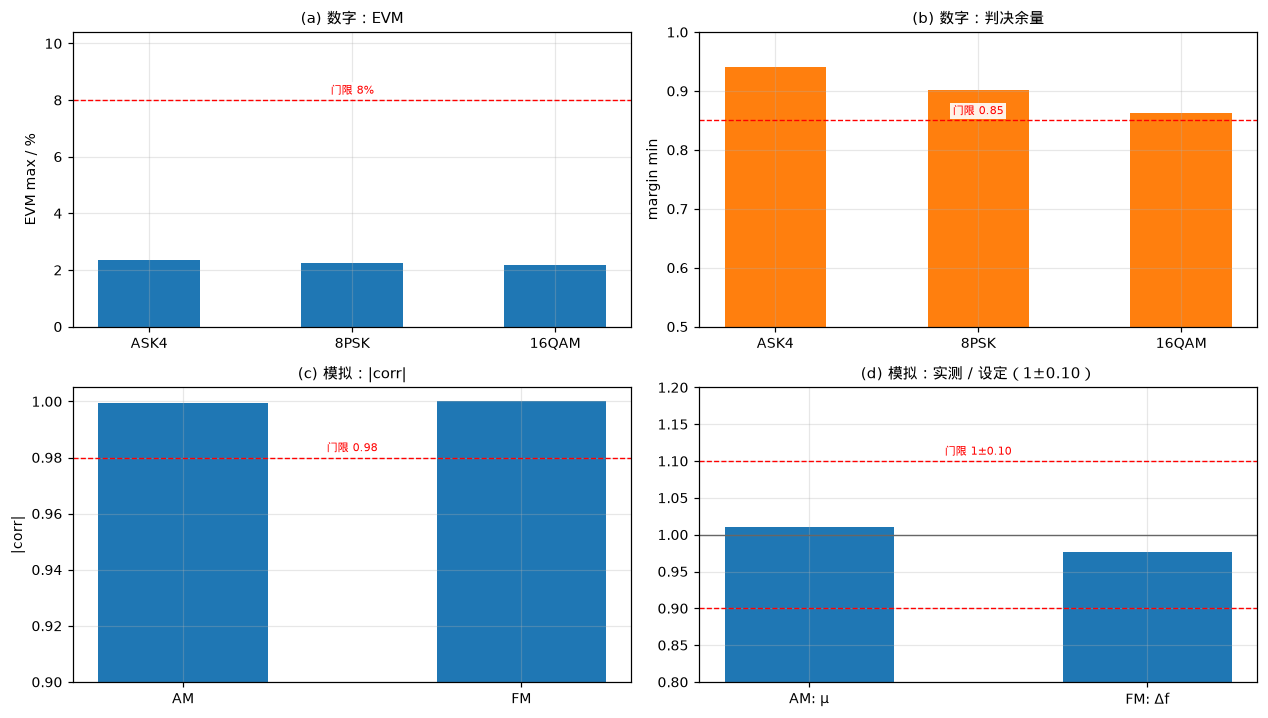

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(11.6, 6.6))


def _note(a, y, text):
    """把门限文字标在虚线上方居中的空白处，替代图例（图例框会压在柱子上）。

    白底 bbox 用来把虚线盖断，否则虚线正好从字中间穿过去。
    """
    a.annotate(text, xy=(0.5, y), xycoords=("axes fraction", "data"),
               xytext=(0, 2.5), textcoords="offset points",
               ha="center", va="bottom", fontsize=7, color="r",
               bbox=dict(fc="white", ec="none", pad=1.5, alpha=0.9))

# (a) 数字：EVM
names = [n for n in ("ASK4", "8PSK", "16QAM") if n in res]
evm = [res[n]["metrics"]["evm_max"] for n in names]
x = np.arange(len(names))
ax[0, 0].bar(x, evm, width=0.5)
ax[0, 0].axhline(C.LIM["evm_max"], color="r", ls="--", lw=0.9)
ax[0, 0].set_ylim(0, 1.3 * C.LIM["evm_max"])
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(names)
ax[0, 0].set_ylabel("EVM max / %")
ax[0, 0].set_title("(a) 数字：EVM")
_note(ax[0, 0], C.LIM["evm_max"], "门限 %.0f%%" % C.LIM["evm_max"])

# (b) 数字：判决余量
mar = [res[n]["metrics"]["margin_min"] for n in names]
ax[0, 1].bar(x, mar, width=0.5, color="C1")
ax[0, 1].axhline(C.LIM["margin_min"], color="r", ls="--", lw=0.9)
ax[0, 1].set_ylim(0.5, 1.0)
ax[0, 1].set_xticks(x); ax[0, 1].set_xticklabels(names)
ax[0, 1].set_ylabel("margin min")
ax[0, 1].set_title("(b) 数字：判决余量")
_note(ax[0, 1], C.LIM["margin_min"], "门限 %.2f" % C.LIM["margin_min"])

# (c) 模拟：相关系数
an = [n for n in ("AM", "FM") if n in res]
corr = [abs(res[n]["metrics"]["corr"]) for n in an]
ax[1, 0].bar(range(len(an)), corr, width=0.5)
ax[1, 0].axhline(C.LIM["corr_min"], color="r", ls="--", lw=0.9)
ax[1, 0].set_ylim(0.9, 1.005)
ax[1, 0].set_xticks(range(len(an))); ax[1, 0].set_xticklabels(an)
ax[1, 0].set_ylabel("|corr|")
ax[1, 0].set_title("(c) 模拟：|corr|")
_note(ax[1, 0], C.LIM["corr_min"], "门限 %.2f" % C.LIM["corr_min"])

# (d) 模拟：实测/设定比值
ratio = [C.ratio_of(res[n]) for n in an]
ax[1, 1].bar(range(len(an)), ratio, width=0.5)
ax[1, 1].axhline(1.0, color="0.4", lw=0.9)
ax[1, 1].axhline(1 + C.LIM["ratio_tol"], color="r", ls="--", lw=0.9)
ax[1, 1].axhline(1 - C.LIM["ratio_tol"], color="r", ls="--", lw=0.9)
ax[1, 1].set_ylim(0.8, 1.2)
ax[1, 1].set_xticks(range(len(an)))
ax[1, 1].set_xticklabels(["AM: μ", "FM: Δf"])
ax[1, 1].set_title("(d) 模拟：实测 / 设定（1±%.2f）" % C.LIM["ratio_tol"])
_note(ax[1, 1], 1 + C.LIM["ratio_tol"],
      "门限 1±%.2f" % C.LIM["ratio_tol"])

plt.tight_layout()
plt.show()

## 3　结论与排错

五个案例共用一条硬件路径、一套同步代码，区别只在星座映射与解调那一层。
判定全 PASS 说明：

1. 数字链路：ZC 前导的定时/频偏估计对任意星座都成立，RRC + 锁相环在 4/8/16 阶下都不误码；
2. 模拟链路：包络检测与正交鉴频在 1000 MHz NCO 环回下保真，AM 的 μ 与 FM 的 Δf 都在 10% 内；
3. DMA 与位流：五个案例的突发长度从 42k 到 532k 字，DMA 均无保持段（否则 BER/EVM 立刻炸）。

| 症状 | 检查顺序 |
|---|---|
| 只有某个数字案例 FAIL | 该案的 `Const.map/demap` 是否对称；`track` 是否适合该星座 |
| 模拟案例 corr 低但数字正常 | 下变频符号 / 幅度门控；看 07 第 3 节的打印 |
| 所有案例 EVM 同时变差 | 环回衰减量、ADC 饱和、NCO 两侧不同频 |
| 所有案例 BER 很高 | 位流不是 128 位版本（TX 保持段）或 ADC 只回 I 通道 |
| 频偏中位 > 1 kHz | LMK/SYSREF；回 `00_init` 重跑时钟 |